# 回归模型验证

本notebook用于训练和评估基于湿度数据预测火灾数量的回归模型。

## 1. 导入必要的库和数据准备

In [1]:
import sys
import os
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

notebook_dir = os.path.abspath('')
project_root = os.path.dirname(os.path.dirname(notebook_dir))

import data_processor
data_processor.DATA_PATH = os.path.join(project_root, 'data', 'processed')
merged_data, humid_cols = data_processor.prepare_weather_fire_data(
    data_type='count',  # 指定计数预测
    weather_types=['humid']  # 只使用湿度数据
)


合并后的数据信息:
数据形状: (1625, 30)
选择的天气类型: ['humid']



## 2. 数据集划分

In [2]:
from sklearn.model_selection import train_test_split

print("\n正在划分数据集...")
(X_train, y_train), (X_val, y_val), (X_test, y_test) = data_processor.split_dataset(
    merged_data=merged_data,
    feature_columns=humid_cols,  # 只使用湿度特征
    target_column='fire_count'
)

# 数据预处理
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_processed = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_val_processed = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)
X_test_processed = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\n数据集形状:")
print(f"训练集: {X_train_processed.shape}")
print(f"验证集: {X_val_processed.shape}")
print(f"测试集: {X_test_processed.shape}")


正在划分数据集...

数据集划分情况:
训练集大小: 975 (60.00%)
验证集大小: 325 (20.00%)
测试集大小: 325 (20.00%)

数据集形状:
训练集: (975, 29)
验证集: (325, 29)
测试集: (325, 29)


## 3. 模型训练与评估


Starting model training and evaluation...

Training Linear Regression...
Linear Regression Evaluation Results:
Mean Squared Error (MSE): 90.5889
Root Mean Squared Error (RMSE): 9.5178
R-squared (R²): 0.4897


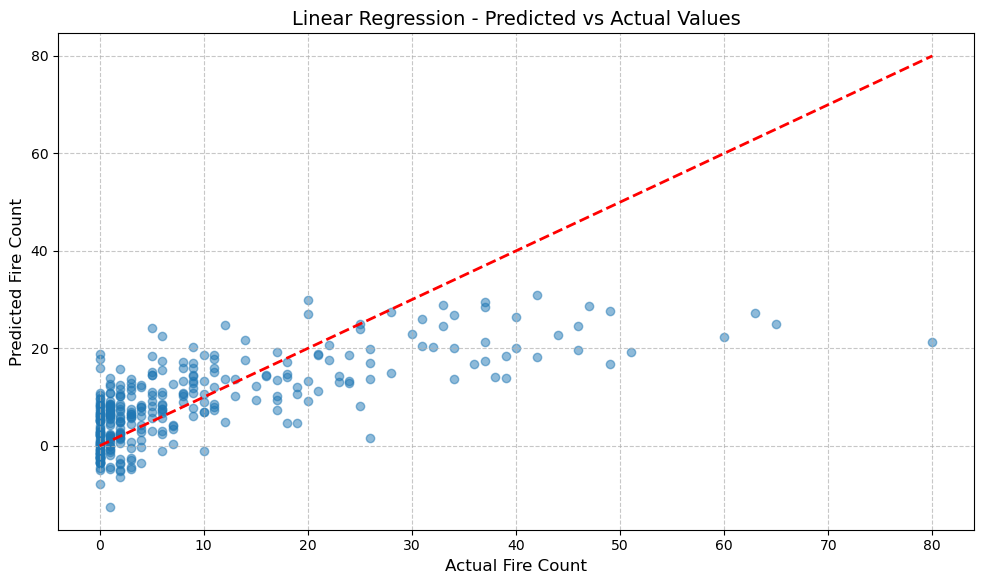

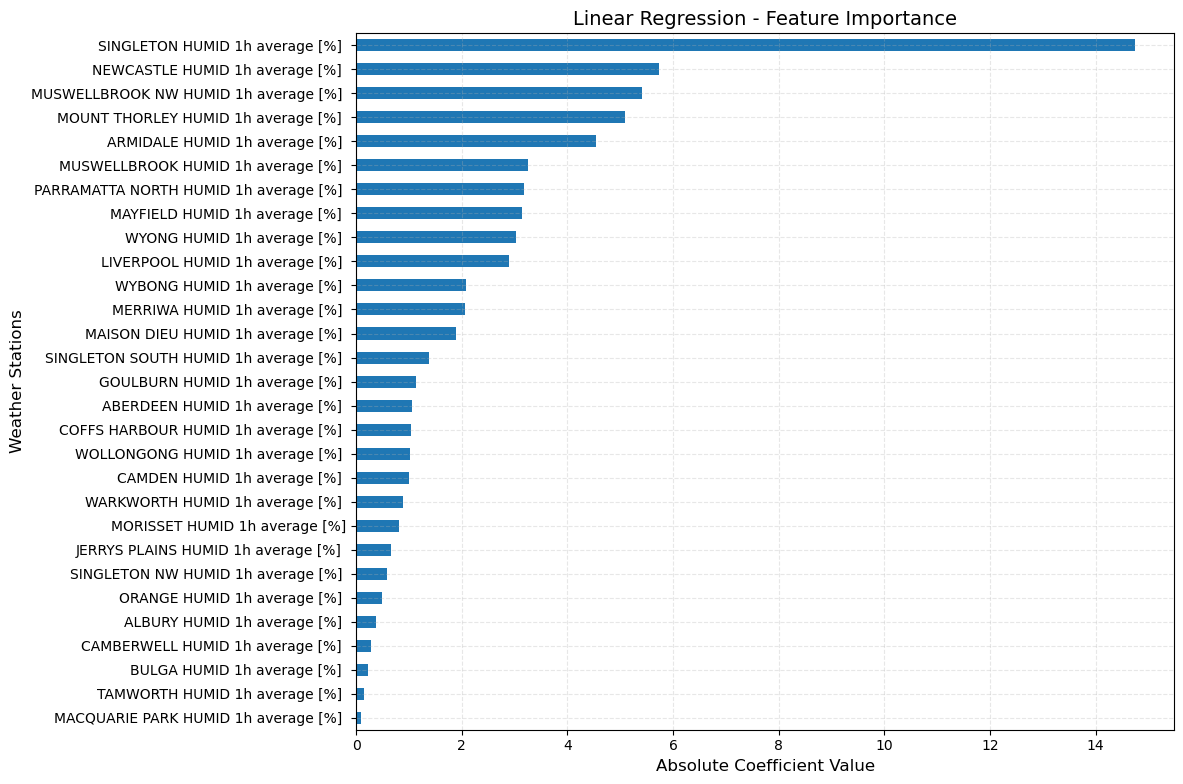


Linear Regression - Top 10 Most Important Features:
LIVERPOOL HUMID 1h average [%]             2.895063
WYONG HUMID 1h average [%]                 3.017710
MAYFIELD HUMID 1h average [%]              3.143777
PARRAMATTA NORTH HUMID 1h average [%]      3.175258
MUSWELLBROOK HUMID 1h average [%]          3.254894
ARMIDALE HUMID 1h average [%]              4.535788
MOUNT THORLEY HUMID 1h average [%]         5.098179
MUSWELLBROOK NW HUMID 1h average [%]       5.406726
NEWCASTLE HUMID 1h average [%]             5.725708
SINGLETON HUMID 1h average [%]            14.746976
dtype: float64

Training Random Forest...
Random Forest Evaluation Results:
Mean Squared Error (MSE): 104.4728
Root Mean Squared Error (RMSE): 10.2212
R-squared (R²): 0.4115


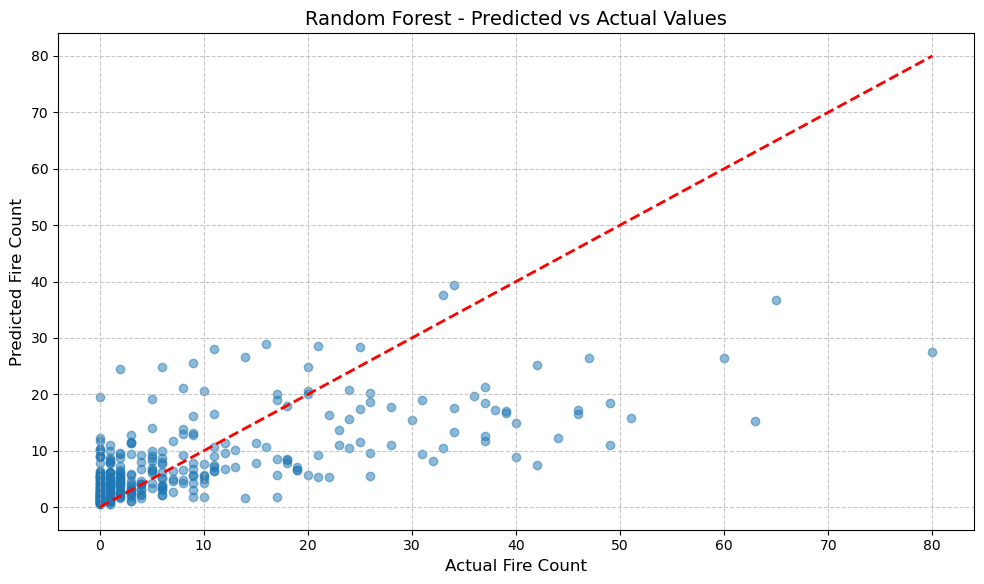

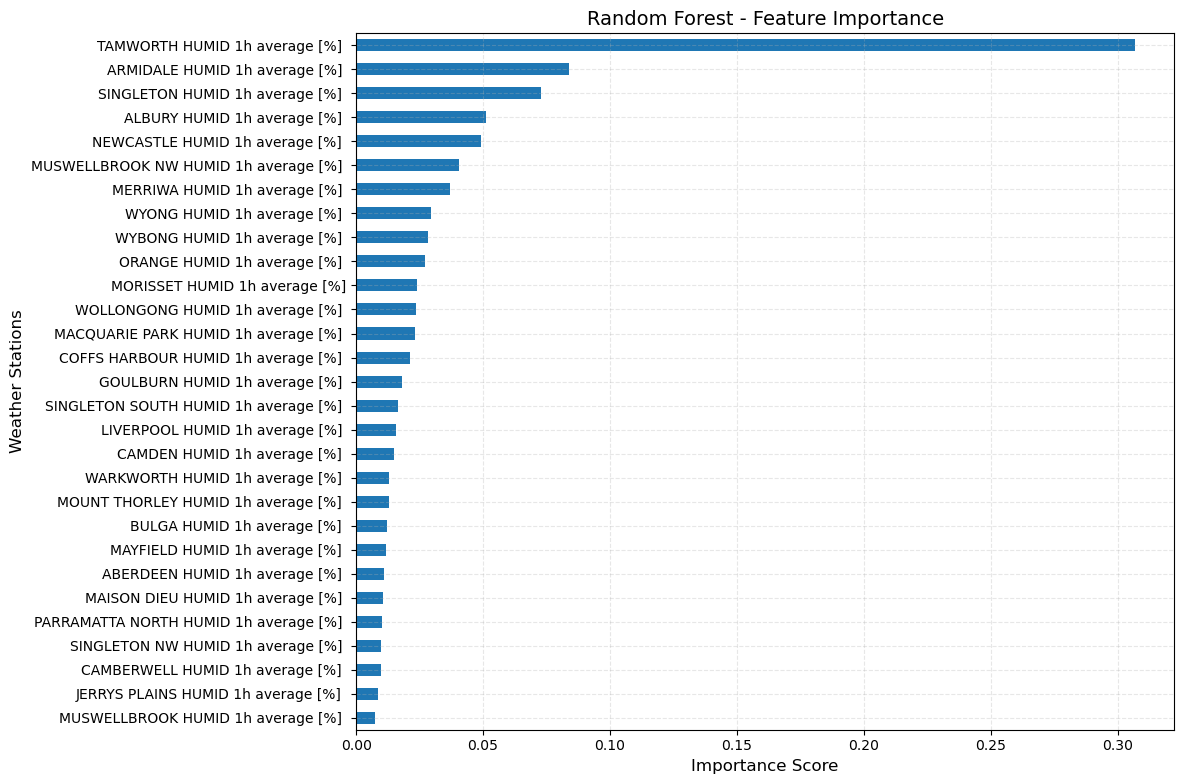


Random Forest - Top 10 Most Important Features:
ORANGE HUMID 1h average [%]              0.027028
WYBONG HUMID 1h average [%]              0.028138
WYONG HUMID 1h average [%]               0.029293
MERRIWA HUMID 1h average [%]             0.037119
MUSWELLBROOK NW HUMID 1h average [%]     0.040705
NEWCASTLE HUMID 1h average [%]           0.049061
ALBURY HUMID 1h average [%]              0.050957
SINGLETON HUMID 1h average [%]           0.072936
ARMIDALE HUMID 1h average [%]            0.083720
TAMWORTH HUMID 1h average [%]            0.306837
dtype: float64

Model Performance Comparison:
                          MSE       RMSE        R²
Linear Regression   90.588884   9.517819  0.489728
Random Forest      104.472806  10.221194  0.411523


C:\Users\18400\AppData\Local\Temp\ipykernel_18512\453808445.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_18512\453808445.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)
C:\Users\18400\AppData\Local\Temp\ipykernel_18512\453808445.py:158: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(model_names, rotation=45)


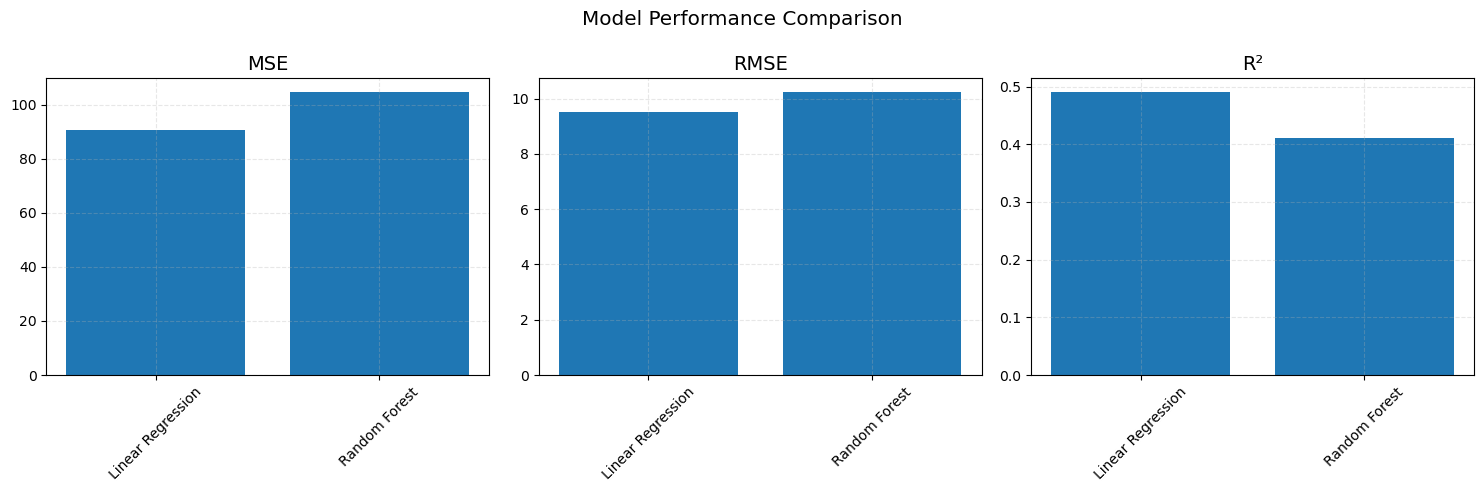

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def train_and_evaluate_models(X_train, X_val, y_train, y_val):
    """
    Train and evaluate regression models
    
    Parameters:
        X_train: Training features
        X_val: Validation features
        y_train: Training target
        y_val: Validation target
        
    Returns:
        Dictionary containing model results
    """
    # Initialize models
    models = {
        'Linear Regression': LinearRegression(),
        'Random Forest': RandomForestRegressor(
            n_estimators=100,  
            max_depth=10,      
            random_state=42
        )
    }
    
    results = {}
    
    for name, model in models.items():
        print(f"\nTraining {name}...")
        # Train model
        model.fit(X_train, y_train)
        
        # Predict
        y_pred = model.predict(X_val)
        
        # Calculate metrics
        mse = mean_squared_error(y_val, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_val, y_pred)
        
        # Print evaluation metrics
        print(f"{name} Evaluation Results:")
        print(f"Mean Squared Error (MSE): {mse:.4f}")
        print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
        print(f"R-squared (R²): {r2:.4f}")
        
        # Scatter plot of predictions vs actual values
        plt.figure(figsize=(10, 6))
        plt.scatter(y_val, y_pred, alpha=0.5)
        plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
        plt.title(f'{name} - Predicted vs Actual Values')
        plt.xlabel('Actual Fire Count')
        plt.ylabel('Predicted Fire Count')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()
        
        # Feature importance plots
        if name == 'Random Forest':
            # Random Forest feature importance
            feature_importance = pd.Series(
                model.feature_importances_,
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            feature_importance.plot(kind='barh')
            plt.title('Random Forest - Feature Importance')
            plt.xlabel('Importance Score')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
        
        if name == 'Linear Regression':
            # Linear Regression feature importance (absolute coefficients)
            linear_importance = pd.Series(
                np.abs(model.coef_),
                index=X_train.columns
            ).sort_values(ascending=True)
            
            plt.figure(figsize=(12, 8))
            linear_importance.plot(kind='barh')
            plt.title('Linear Regression - Feature Importance')
            plt.xlabel('Absolute Coefficient Value')
            plt.ylabel('Weather Stations')
            plt.grid(True, linestyle='--', alpha=0.3)
            plt.tight_layout()
            plt.show()
            
        # Store results
        results[name] = {
            'model': model,
            'mse': mse,
            'rmse': rmse,
            'r2': r2,
            'predictions': y_pred
        }
        
        # Print feature importance rankings
        if name == 'Random Forest':
            print("\nRandom Forest - Top 10 Most Important Features:")
            print(feature_importance.tail(10))
        
        if name == 'Linear Regression':
            print("\nLinear Regression - Top 10 Most Important Features:")
            print(linear_importance.tail(10))
    
    # Compare model performances
    print("\nModel Performance Comparison:")
    performance_comparison = pd.DataFrame({
        'MSE': [results[model]['mse'] for model in models],
        'RMSE': [results[model]['rmse'] for model in models],
        'R²': [results[model]['r2'] for model in models]
    }, index=models.keys())
    print(performance_comparison)
    
    return results


# Configure plot settings for better readability
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Train and evaluate models
print("\nStarting model training and evaluation...")
model_results = train_and_evaluate_models(X_train_processed, X_val_processed, y_train, y_val)

# Additional visualization: Model performance comparison
metrics = ['MSE', 'RMSE', 'R²']
model_names = list(model_results.keys())
performance_data = []

for metric in metrics:
    if metric == 'MSE':
        values = [results['mse'] for results in model_results.values()]
    elif metric == 'RMSE':
        values = [results['rmse'] for results in model_results.values()]
    else:  # R²
        values = [results['r2'] for results in model_results.values()]
    performance_data.append(values)

# Plot model performance comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Model Performance Comparison')

for i, (metric, ax) in enumerate(zip(metrics, axes)):
    ax.bar(model_names, performance_data[i])
    ax.set_title(metric)
    ax.set_xticklabels(model_names, rotation=45)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()